# 06 — csPCa Classification with XGBoost (grouped_v2)

## Objective

This notebook implements the classification stage of the pipeline using
whole-gland radiomic features extracted from T2W MRI.

The workflow includes:

1. Loading the radiomic feature dataset
2. Adding the csPCa target and patient-level data split
3. Validating the classification dataset
4. Preparing training, validation, and test sets
5. Training the XGBoost classifier
6. Evaluating classification performance

The binary target is `case_csPCa`, where positive cases represent
clinically significant prostate cancer.

## 1. Imports and paths

In [10]:
from pathlib import Path
import json
import time
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (accuracy_score, average_precision_score,
                             balanced_accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score,
                             PrecisionRecallDisplay, recall_score,
                             roc_auc_score, RocCurveDisplay, roc_curve)
from xgboost import XGBClassifier

RANDOM_STATE = 42
EXPECTED_FEATURES = 107
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "notebooks" else cwd
features_path = PROJECT_ROOT / "src/data/features/whole_gland_t2w_radiomics_grouped_v2.csv"
clinical_path = PROJECT_ROOT / "src/data/raw/picai_labels/clinical_information/marksheet.csv"
splits_path = PROJECT_ROOT / "src/data/processed/splits/patient_splits_grouped_v2.csv"
# Save this experiment separately from historical classification results.
results_dir = PROJECT_ROOT / "results/classification/grouped_v2_xgboost"
for name, path in [("Features", features_path), ("Clinical", clinical_path), ("Splits", splits_path)]:
    print(f"{name}: {path} | exists={path.is_file()}")


Features: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\features\whole_gland_t2w_radiomics_grouped_v2.csv | exists=True
Clinical: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\raw\picai_labels\clinical_information\marksheet.csv | exists=True
Splits: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\processed\splits\patient_splits_grouped_v2.csv | exists=True


## 2. Load radiomics, clinical target, and predefined splits

In [11]:
id_columns = ["patient_id", "study_id"]
features_df = pd.read_csv(features_path, dtype={c: str for c in id_columns})
clinical_df = pd.read_csv(clinical_path, dtype={c: str for c in id_columns})
splits_df = pd.read_csv(splits_path, dtype={c: str for c in id_columns})

feature_columns = [column for column in features_df.columns if column.startswith("original_")]
assert len(feature_columns) == EXPECTED_FEATURES, f"Expected 107 radiomic features, got {len(feature_columns)}"
for name, frame in [("radiomics", features_df), ("clinical", clinical_df), ("splits", splits_df)]:
    assert not frame.duplicated(id_columns).any(), f"Duplicate examination keys in {name}"

assert len(features_df) == len(clinical_df) == len(splits_df) == 1500, "Expected 1,500 source examinations"

classification_df = (features_df
    .merge(clinical_df[id_columns + ["case_csPCa"]], on=id_columns, how="inner", validate="one_to_one")
    .merge(splits_df[id_columns + ["split"]], on=id_columns, how="inner", validate="one_to_one"))
assert len(classification_df) == 1500, "Merge dropped examinations; verify identifiers"
assert set(map(tuple, features_df[id_columns].to_numpy())) == set(map(tuple, classification_df[id_columns].to_numpy())), "Missing or extra cases after merge"
# The grouped-v2 CSV uses `val`; retain the notebook's `validation` key.
classification_df["split"] = classification_df["split"].replace({"val": "validation"})
classification_df["target"] = classification_df["case_csPCa"].map({"NO": 0, "YES": 1})
assert classification_df["target"].notna().all(), "Unexpected target labels"
assert classification_df["split"].isin(["train", "validation", "test"]).all()
classification_df["target"] = classification_df["target"].astype(int)
print("Examinations:", len(classification_df))
print("Unique patients:", classification_df.patient_id.nunique())
display(pd.crosstab(classification_df["split"], classification_df["target"]))


Examinations: 1500
Unique patients: 1476


C:\Users\Luiz Trindade\AppData\Local\Temp\ipykernel_17508\2475207497.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  classification_df["target"] = classification_df["case_csPCa"].map({"NO": 0, "YES": 1})


target,0,1
split,,
test,161,64
train,752,297
validation,162,64


## 3. Validate the grouped-v2 classification dataset

Confirm that all 1,500 examinations are included, the grouped-v2 split matches expected sizes, and no patient appears in multiple partitions. Abort training if these checks fail.


In [12]:
patient_split_counts = classification_df.groupby("patient_id")["split"].nunique()
n_overlapping = int((patient_split_counts > 1).sum())
print("Patients in multiple partitions:", n_overlapping)
print("Missing radiomic entries:", int(classification_df[feature_columns].isna().sum().sum()))
print("Infinite radiomic entries:", int(np.isinf(classification_df[feature_columns].to_numpy(dtype=float)).sum()))
assert n_overlapping == 0, "Patient leakage detected; stop before training"
assert len(classification_df) == 1500, "Incomplete merged dataset"
assert classification_df["split"].value_counts().to_dict() == {"train": 1049, "validation": 226, "test": 225}, "Unexpected grouped-v2 split sizes"
assert int(classification_df["target"].sum()) == 425, "Unexpected positive-case total"
assert classification_df.groupby("split")["target"].sum().to_dict() == {"train": 297, "validation": 64, "test": 64}, "Unexpected positive counts by split"
print("Grouped-v2 split validated: patient-disjoint, with expected case counts.")


Patients in multiple partitions: 0
Missing radiomic entries: 0
Infinite radiomic entries: 0
Grouped-v2 split validated: patient-disjoint, with expected case counts.


## 4. Prepare training, validation, and test sets

In [13]:
split_frames = {split: classification_df.loc[classification_df["split"] == split].copy()
                for split in ["train", "validation", "test"]}
X = {split: frame[feature_columns].copy() for split, frame in split_frames.items()}
y = {split: frame["target"].copy() for split, frame in split_frames.items()}
for split in ["train", "validation", "test"]:
    assert np.isfinite(X[split].to_numpy(dtype=float)).all(), f"Nonfinite radiomics in {split}"
    print(split, X[split].shape, y[split].value_counts().to_dict())


train (1049, 107) {0: 752, 1: 297}
validation (226, 107) {0: 162, 1: 64}
test (225, 107) {0: 161, 1: 64}


## 5. Train XGBoost classifier

The parameters below reflect the historical configuration preserved in the discussion (150 trees, depth 3, learning rate 0.03, and stronger regularization). This reconstruction does **not** reproduce the missing hyperparameter-search history.

In [14]:
negative_count = int((y["train"] == 0).sum())
positive_count = int((y["train"] == 1).sum())
scale_pos_weight = negative_count / positive_count

xgb_parameters = dict(
    n_estimators=150,
    max_depth=3,
    learning_rate=0.03,
    min_child_weight=10,
    reg_alpha=0.5,
    reg_lambda=10.0,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
start = time.perf_counter()
xgb_model = XGBClassifier(**xgb_parameters)
xgb_model.fit(X["train"], y["train"])
print(f"Training time: {time.perf_counter() - start:.2f} s")


Training time: 0.48 s


## 6. Evaluate on validation and select the threshold

The historical record mentions a selected threshold of approximately `0.4787`. It may not reproduce exactly without the original execution and hyperparameter-selection history. The cell below **recomputes** a validation-only Youden threshold rather than hardcoding a historical value.

In [15]:
validation_scores = xgb_model.predict_proba(X["validation"])[:, 1]
print("Validation ROC-AUC:", round(roc_auc_score(y["validation"], validation_scores), 4))
print("Validation AP:", round(average_precision_score(y["validation"], validation_scores), 4))
fpr, tpr, thresholds = roc_curve(y["validation"], validation_scores)
finite = np.isfinite(thresholds)
youden = tpr[finite] - fpr[finite]
selected_threshold = float(thresholds[finite][np.argmax(youden)])
print("Validation-selected Youden threshold:", selected_threshold)


Validation ROC-AUC: 0.6477
Validation AP: 0.4049
Validation-selected Youden threshold: 0.5897423028945923


## 7. Test-set evaluation

Evaluate the grouped-v2 held-out test set once, after fixing the training configuration and selecting the classification threshold exclusively on validation. No parameter adjustments should be made in response to test results.


In [16]:
test_scores = xgb_model.predict_proba(X["test"])[:, 1]
test_predictions = (test_scores >= selected_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y["test"], test_predictions, labels=[0, 1]).ravel()
test_metrics = {
    "threshold": selected_threshold,
    "roc_auc": roc_auc_score(y["test"], test_scores),
    "average_precision": average_precision_score(y["test"], test_scores),
    "accuracy": accuracy_score(y["test"], test_predictions),
    "balanced_accuracy": balanced_accuracy_score(y["test"], test_predictions),
    "sensitivity": recall_score(y["test"], test_predictions),
    "specificity": tn / (tn + fp),
    "precision": precision_score(y["test"], test_predictions, zero_division=0),
    "f1_score": f1_score(y["test"], test_predictions, zero_division=0),
    "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
}
display(pd.DataFrame([test_metrics]).round(4))


,threshold,roc_auc,average_precision,accuracy,balanced_accuracy,sensitivity,specificity,precision,f1_score,tn,fp,fn,tp
0,0.5897,0.6732,0.4316,0.6667,0.6023,0.4531,0.7516,0.4203,0.4361,121,40,35,29


## 8. Classification plots

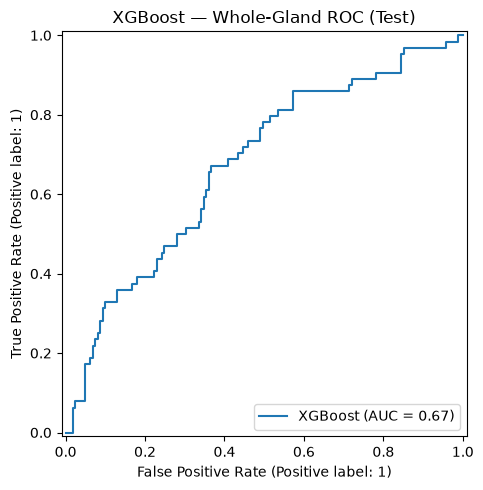

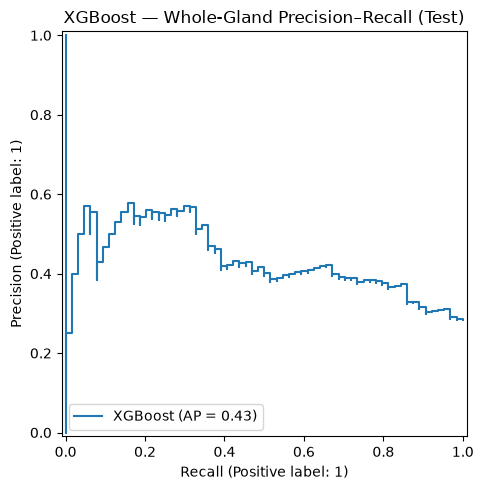

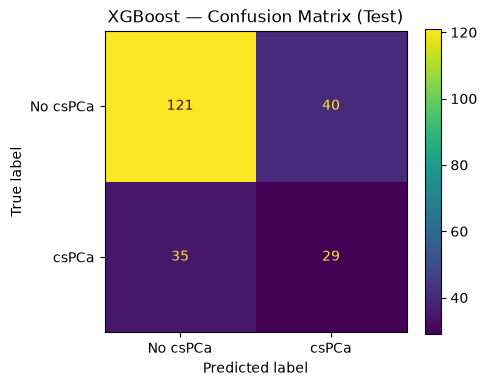

In [17]:
results_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y["test"], test_scores, name="XGBoost", ax=ax)
ax.set_title("XGBoost — Whole-Gland ROC (Test)")
fig.tight_layout()
fig.savefig(results_dir / "test_roc_curve.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y["test"], test_scores, name="XGBoost", ax=ax)
ax.set_title("XGBoost — Whole-Gland Precision–Recall (Test)")
fig.tight_layout()
fig.savefig(results_dir / "test_pr_curve.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y["test"], test_predictions,
    labels=[0, 1], display_labels=["No csPCa", "csPCa"], ax=ax)
ax.set_title("XGBoost — Confusion Matrix (Test)")
fig.tight_layout()
fig.savefig(results_dir / "test_confusion_matrix.png", dpi=160)
plt.show()


## 9. Save model and results

Save this grouped-v2 run in its own output directory, leaving historical artifacts untouched. The notebook retains the documented reconstructed XGBoost configuration; it does not recover an unavailable historical parameter-search record.


In [18]:
joblib.dump(xgb_model, results_dir / "xgboost_grouped_v2.joblib")
xgb_model.save_model(str(results_dir / "xgboost_grouped_v2.json"))
pd.DataFrame([test_metrics]).to_csv(results_dir / "test_metrics_grouped_v2.csv", index=False)
predictions_df = split_frames["test"][id_columns + ["target"]].copy()
predictions_df["score"] = test_scores
predictions_df["prediction"] = test_predictions
predictions_df.to_csv(results_dir / "test_predictions_grouped_v2.csv", index=False)
metadata = {
    "provenance": "grouped_v2; reconstructed historical XGBoost configuration",
    "notebook_title": "06 — csPCa Classification with XGBoost",
    "input_features": str(features_path),
    "input_splits": str(splits_path),
    "n_features": len(feature_columns),
    "feature_names": feature_columns,
    "model_parameters": xgb_parameters,
    "selected_threshold": selected_threshold,
    "patient_overlap_between_splits": n_overlapping,
}
with open(results_dir / "metadata_grouped_v2.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, default=str)
print("Grouped-v2 artifacts saved to:", results_dir)


Grouped-v2 artifacts saved to: C:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\results\classification\grouped_v2_xgboost
